In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [8]:
def simulate_g2p_dynamics(t, states, parameters):
    # Simulates transient scrubber storage volume (m3) and
    # engine block temperature (K) over 1-hour timeline under fluctuating
    # well pressure.
    V_gas, T_engine = states

    # Real world dynamic inflow
    Q_in = parameters['Q_baseline'] + 0.01 * np.sin(2 * np.pi * t / 1800)
    Q_in = max(0.0, Q_in)

    # Automated engine generator consumption logic
    if V_gas > 0.02:
        Q_engine = min(parameters['Q_max_intake'], V_gas / 1.0)
    else:
        Q_engine = 0.0

    # Energy balance (40% electrical generation, 70% CHP Wasted Heat Capture)
    Total_Watts_In = Q_engine * parameters['L_lhv']
    P_electrical = Total_Watts_In * parameters['eta_elec']
    P_thermal_recovered = Total_Watts_In * (1 - parameters['eta_elec']) * parameters['eta_chp']

    # Exact unrecovered wasted heat load applied in Simscale
    unrecovered_waste_heat = Total_Watts_In - P_electrical - P_thermal_recovered

    # Systems ODE
    dV_gas_dt = Q_in - Q_engine
    Q_cooling_vent = parameters['h_ventilation'] * (T_engine - parameters['T_ambient'])
    dT_engine_dt = (unrecovered_waste_heat - Q_cooling_vent) / parameters['C_p_engine']

    return [dV_gas_dt, dT_engine_dt]

# 1MW Modular Generator Set
config = {
    'Q_baseline': 0.0475,      # Standard flow matching ~1.5 million m3/year well flare
    'Q_max_intake': 0.060,     # Max physical gas valve consumption limit
    'L_lhv': 35.8e6,           # Lower Heating Value of pure Methane gas (J/m3)
    'eta_elec': 0.40,          # 40% Electrical efficiency baseline
    'eta_chp': 0.70,           # 70% Capture efficiency via exhaust heat jacket
    'C_p_engine': 9.5e5,       # Combined solid metal thermal mass index (J/K)
    'h_ventilation': 1800,     # Suction fan convective cooling coefficient (W/K)
    'T_ambient': 303.15        # Operations climate baseline (30°C / 303.15 K)
}

In [9]:
# Combined definition cell above

In [10]:
# Execution of Integrated System
time_horizon = (0, 3600)  # Simulate exactly 1 hour of operational time
time_eval_steps = np.linspace(0, 3600, 500)
initial_conditions = [0.1, 303.15] # 0.1m3 start gas, engine sitting cold at 30°C

results = solve_ivp(simulate_g2p_dynamics, time_horizon, initial_conditions, args=(config,), t_eval=time_eval_steps)

In [11]:
# Post-Processing Performance Summary
mean_gas_burned = np.mean([min(config['Q_max_intake'], v / 1.0) if v > 0.02 else 0.0 for v in results.y[0]])
total_gas_processed_m3 = mean_gas_burned * 3600


In [12]:
# Emission Reduction Metric: Net kilograms of raw greenhouse gas blocked from atmosphere
# (Engine cylinders destroy 99.5% of methane vs open flares which burn poorly at 92%)
dre_flare_baseline = 0.92
dre_controlled_engine = 0.995
methane_density_kg_m3 = 0.657
methane_saved_kg = total_gas_processed_m3 * (dre_controlled_engine - dre_flare_baseline) * methane_density_kg_m3


In [13]:
# Power Metrics
final_power_kw = (mean_gas_burned * config['L_lhv'] * config['eta_elec']) / 1e3
final_heat_kw = (mean_gas_burned * config['L_lhv'] * (1 - config['eta_elec']) * config['eta_chp']) / 1e3
net_efficiency = (config['eta_elec'] + (1 - config['eta_elec']) * config['eta_chp']) * 100


In [15]:
print(f"⚡ Average Electrical Output: {final_power_kw:.2f} kW")
print(f"♨️ Recovered Thermal CHP Output: {final_heat_kw:.2f} kW")
print(f"📈 Combined Resource Efficiency: {net_efficiency:.1f}%")
print(f"🌍 Climate Footprint Reduction: {methane_saved_kg:.2f} kg Methane/hour saved")


⚡ Average Electrical Output: 680.65 kW
♨️ Recovered Thermal CHP Output: 714.69 kW
📈 Combined Resource Efficiency: 82.0%
🌍 Climate Footprint Reduction: 8.43 kg Methane/hour saved


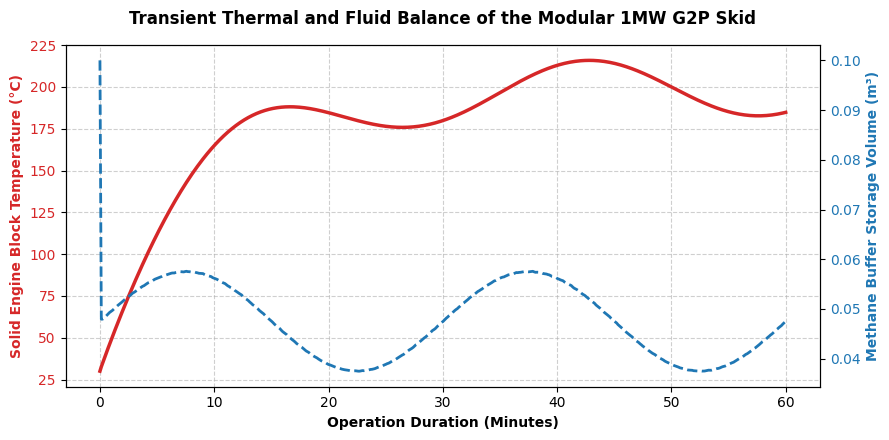

In [17]:
# Plots
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color = 'tab:red'
ax1.set_xlabel('Operation Duration (Minutes)', fontweight='bold')
ax1.set_ylabel('Solid Engine Block Temperature (°C)', color=color, fontweight='bold')
ax1.plot(results.t / 60, results.y[1] - 273.15, color=color, linewidth=2.5, label='Engine Temp.')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Methane Buffer Storage Volume (m³)', color=color, fontweight='bold')
ax2.plot(results.t / 60, results.y[0], color=color, linestyle='--', linewidth=2, label='Buffer Gas')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Transient Thermal and Fluid Balance of the Modular 1MW G2P Skid', fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig('g2p_system_performance.png', dpi=300)
